# Heart Disease Risk - Exploratory Data Analysis

**Author:** J Sai Anvesh Reddy (BITS ID: 2025AE05969)
**Course:** AIMLCZG523 - MLOps, Assignment 1

This notebook covers Task 1 (Data Acquisition & EDA) and part of Task 2 (feature engineering rationale). The modelling and MLflow-tracked training itself lives in `src/heart_mlops/train.py` so it can run both interactively and from CI - this notebook is where I explore the data and justify the choices that script makes.

## 1. Data acquisition

Dataset: **Heart Disease UCI (Cleveland subset)**, 303 patient records, 14 attributes (13 features + target), sourced from the [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/45/heart+disease).

The raw file `processed.cleveland.data` ships with this repo under `data/raw/` so the notebook runs offline and reproducibly. To re-download it from scratch instead:

```bash
curl -o data/raw/processed.cleveland.data \
  https://archive.ics.uci.edu/static/public/45/data/processed.cleveland.data
```

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, '../src')

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from heart_mlops.config import RAW_COLUMNS, RAW_DATA_PATH
from heart_mlops.data import clean_data, load_raw_data
from heart_mlops.features import add_engineered_features

sns.set_theme(style='whitegrid', palette='viridis')
pd.set_option('display.max_columns', 20)

FIGDIR = Path('../report/images')
FIGDIR.mkdir(parents=True, exist_ok=True)

## 2. Raw data inspection

The raw file has no header row and uses `?` for missing values, so both are handled at load time in `heart_mlops.data.load_raw_data`.

In [2]:
raw_df = load_raw_data(RAW_DATA_PATH)
print(raw_df.shape)
raw_df.head()

(303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [3]:
raw_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  num       303 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 33.3 KB


Two columns carry missing values after the `?` -> NaN conversion: `ca` (number of major vessels coloured by fluoroscopy) and `thal` (thalassemia test result). Let's confirm how many rows are affected before deciding how to handle them.

In [4]:
missing_counts = raw_df.isna().sum()
missing_counts[missing_counts > 0]

ca      4
thal    2
dtype: int64

Only **6 of 303 rows** (~2%) are affected, all confined to `ca`/`thal`. Dropping them is the 'textbook' approach seen in most public notebooks on this dataset, but with a sample this small I'd rather not throw away 2% of an already tiny dataset for two columns. Both are effectively categorical (`ca` is a vessel count 0-3, `thal` is a 3-way test code), so I impute each with its **mode** - see `heart_mlops.data.clean_data` for the implementation.

In [5]:
clean_df = clean_data(raw_df)
clean_df.isna().sum().sum(), clean_df.shape

(0, (303, 14))

## 3. Target variable

The raw `num` column is disease severity on a 0-4 scale. The assignment calls for a **binary** target, and this also matches how the original Cleveland study itself is usually consumed (0 = no disease, >0 = disease present of varying severity) - collapsing to binary trades away severity information we don't need for a risk classifier.

In [6]:
counts = clean_df['target'].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(['No disease (0)', 'Disease present (1)'], counts.values,
       color=['#4C72B0', '#DD8452'])
ax.set_ylabel('Patient count')
ax.set_title('Class balance - target variable')
for i, v in enumerate(counts.values):
    ax.text(i, v + 3, str(v), ha='center')
plt.tight_layout()
fig.savefig(FIGDIR / 'class_balance.png', dpi=150)
plt.show()
counts / counts.sum()

<Figure size 500x400 with 1 Axes>

target
0    0.541254
1    0.458746
Name: count, dtype: float64

Class split is roughly **54/46**, not perfectly balanced but nowhere near the severe imbalance that would force resampling (SMOTE etc.) - plain stratified train/test splitting and CV folds are enough here, which is simpler and easier to defend than adding a resampler for a 54/46 split.

## 4. Univariate distributions

Histograms for the continuous features, to check scale differences (which motivates the `StandardScaler` step in the preprocessing pipeline) and spot any obvious skew or outliers.

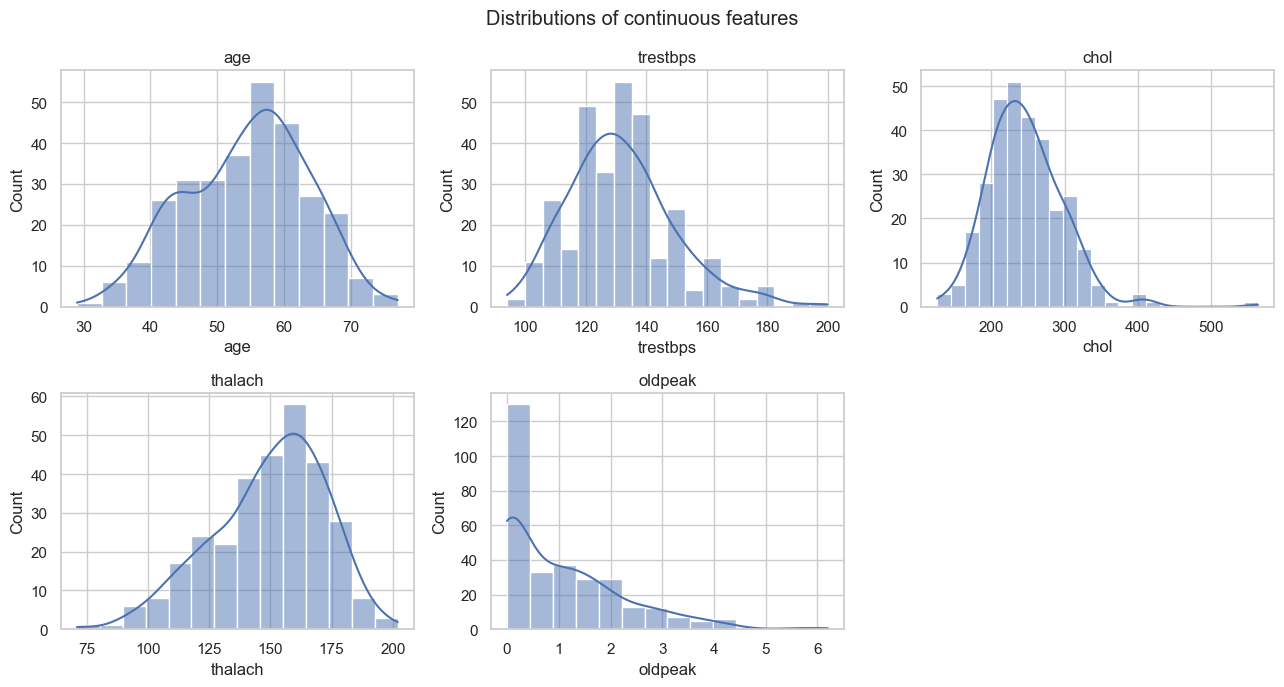

In [7]:
numeric_cols = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, col in zip(axes.flat, numeric_cols):
    sns.histplot(clean_df[col], kde=True, ax=ax, color='#4C72B0')
    ax.set_title(col)
axes.flat[-1].axis('off')
plt.suptitle('Distributions of continuous features')
plt.tight_layout()
fig.savefig(FIGDIR / 'numeric_histograms.png', dpi=150)
plt.show()

`chol` and `oldpeak` are right-skewed with a handful of high-value outliers (likely genuine extreme readings rather than data errors, given the clinical plausibility of the ranges) - tree-based models won't care, but it's worth knowing before trusting Logistic Regression's coefficients at face value.

## 5. Feature relationships with the target

C:\Users\PC\AppData\Local\Temp\ipykernel_37860\1871185053.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=clean_df, x='target', y=col, ax=ax, palette=['#4C72B0', '#DD8452'])
C:\Users\PC\AppData\Local\Temp\ipykernel_37860\1871185053.py:4: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['No disease', 'Disease'])
C:\Users\PC\AppData\Local\Temp\ipykernel_37860\1871185053.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=clean_df, x='target', y=col, ax=ax, palette=['#4C72B0', '#DD8452'])
C:\Users\PC\AppData\Local\Temp\ipykernel_37860\1871185053.py:4: UserWarning: set_ticklabels(

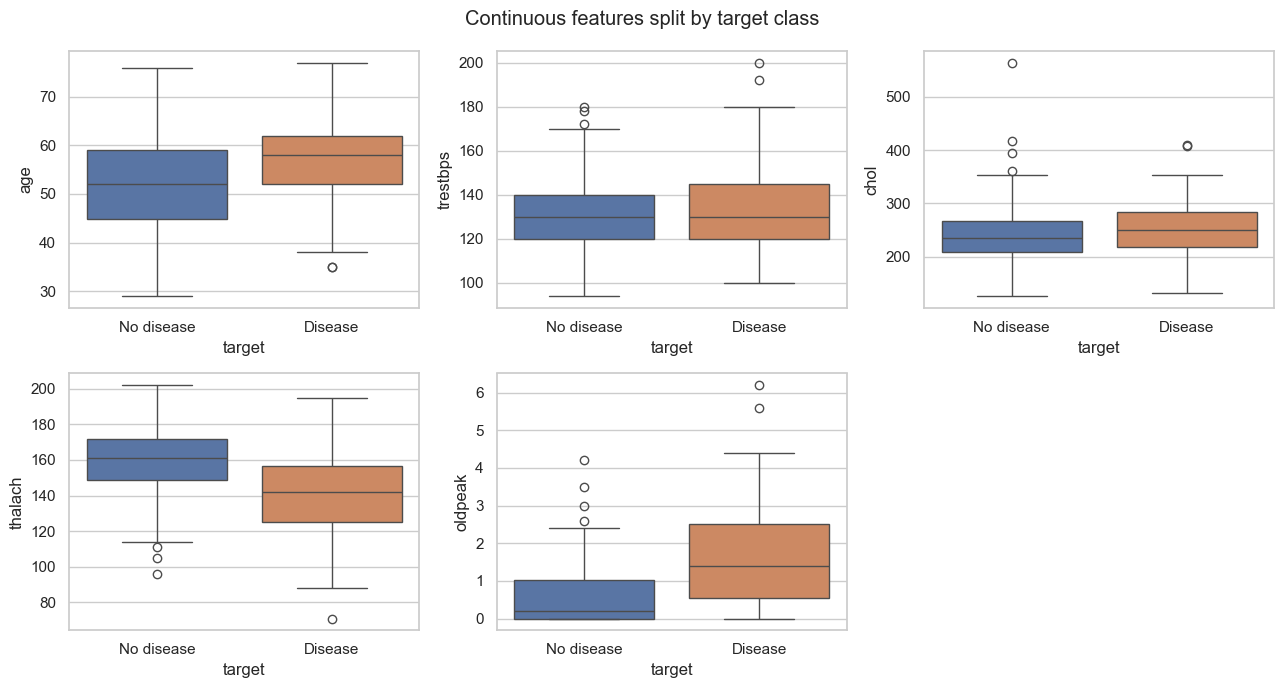

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, col in zip(axes.flat, numeric_cols):
    sns.boxplot(data=clean_df, x='target', y=col, ax=ax, palette=['#4C72B0', '#DD8452'])
    ax.set_xticklabels(['No disease', 'Disease'])
axes.flat[-1].axis('off')
plt.suptitle('Continuous features split by target class')
plt.tight_layout()
fig.savefig(FIGDIR / 'boxplots_by_target.png', dpi=150)
plt.show()

`thalach` (max heart rate achieved) separates the classes most visibly on its own - patients with disease tend to hit a lower peak heart rate under exercise. That observation is what motivated the engineered `hr_reserve` feature below rather than leaving it implicit.

C:\Users\PC\AppData\Local\Temp\ipykernel_37860\2351185355.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=eng_df, x='target', y='hr_reserve', ax=ax, palette=['#4C72B0', '#DD8452'])
C:\Users\PC\AppData\Local\Temp\ipykernel_37860\2351185355.py:4: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['No disease', 'Disease'])


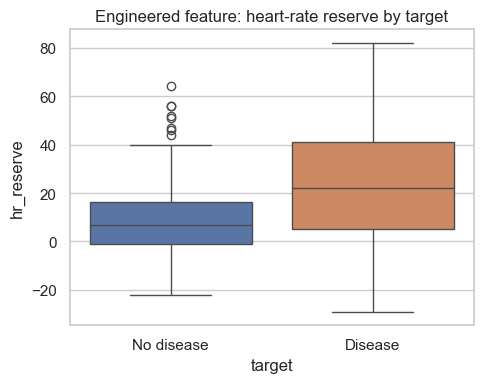

In [9]:
eng_df = add_engineered_features(clean_df)
fig, ax = plt.subplots(figsize=(5, 4))
sns.boxplot(data=eng_df, x='target', y='hr_reserve', ax=ax, palette=['#4C72B0', '#DD8452'])
ax.set_xticklabels(['No disease', 'Disease'])
ax.set_title('Engineered feature: heart-rate reserve by target')
plt.tight_layout()
fig.savefig(FIGDIR / 'hr_reserve_boxplot.png', dpi=150)
plt.show()

## 6. Correlation heatmap

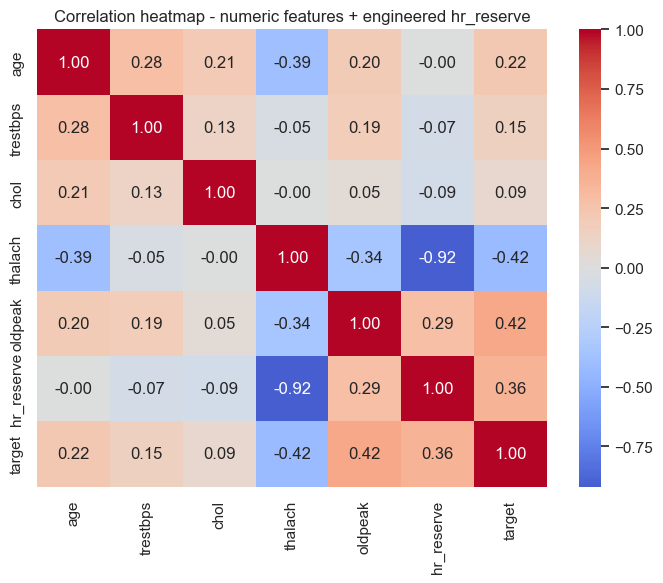

In [10]:
corr_cols = numeric_cols + ['hr_reserve', 'target']
corr = eng_df[corr_cols].corr()
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax)
ax.set_title('Correlation heatmap - numeric features + engineered hr_reserve')
plt.tight_layout()
fig.savefig(FIGDIR / 'correlation_heatmap.png', dpi=150)
plt.show()

Checking the actual numbers rather than just eyeballing the boxplot: `hr_reserve`'s linear correlation with `target` (0.36) is honestly a touch *weaker* than `thalach`'s on its own (-0.42) - Pearson correlation is being dragged down by the long tail of outliers visible in the no-disease group's boxplot above, while the median-to-median separation stays clearly visible. As expected from the formula, it is almost perfectly anti-correlated with `thalach` (-0.92), so it isn't adding independent signal - what it adds is **interpretability**: a single clinically-named number (predicted max HR minus achieved max HR) instead of asking a reader to mentally recombine two raw columns. I kept it for that reason, not because it beats `thalach` on correlation alone; Task 2's model comparison is what ultimately judges whether it earns its place.

## 7. Categorical features vs. target

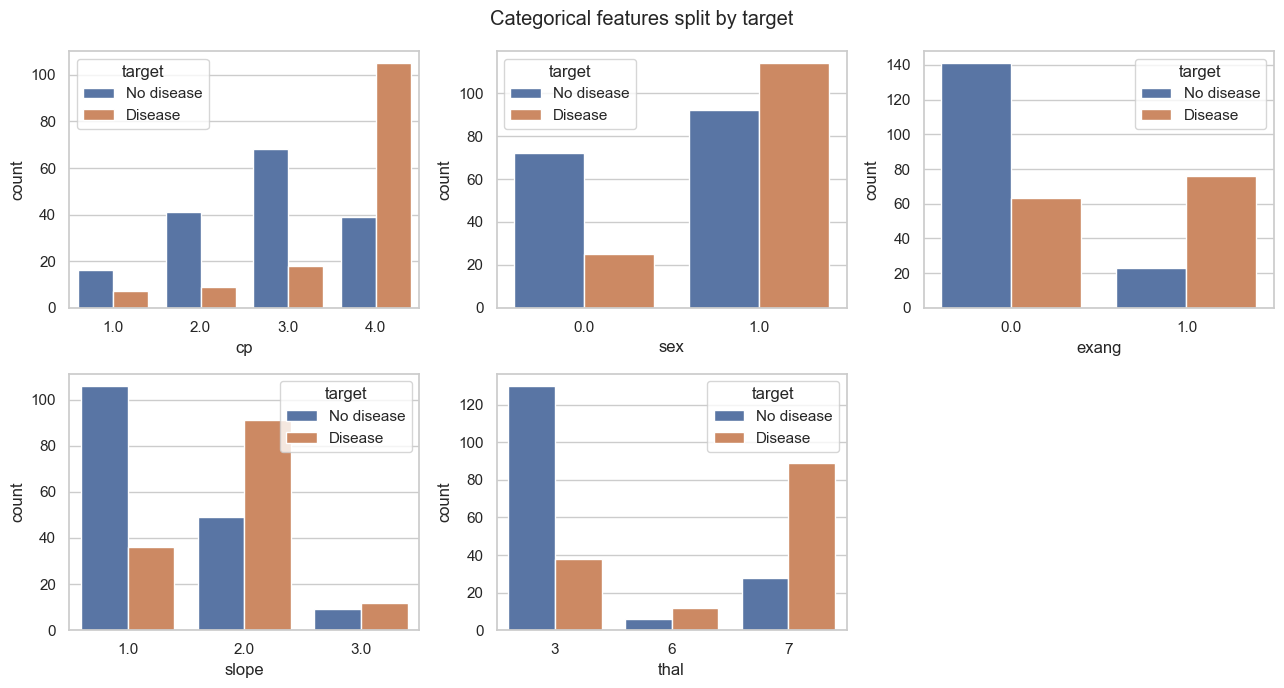

In [11]:
cat_cols = ['cp', 'sex', 'exang', 'slope', 'thal']
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, col in zip(axes.flat, cat_cols):
    sns.countplot(data=clean_df, x=col, hue='target', ax=ax, palette=['#4C72B0', '#DD8452'])
    ax.legend(title='target', labels=['No disease', 'Disease'])
axes.flat[-1].axis('off')
plt.suptitle('Categorical features split by target')
plt.tight_layout()
fig.savefig(FIGDIR / 'categorical_vs_target.png', dpi=150)
plt.show()

`cp` (chest pain type) and `thal` show the clearest separation by eye - both are multi-category (not binary), which is why the preprocessing pipeline one-hot encodes them instead of treating them as ordinal integers (an integer encoding would wrongly imply e.g. chest-pain-type 3 is 'between' types 2 and 4).

## 8. Summary of decisions carried into `src/heart_mlops/`

- **Missing values**: mode-imputed on `ca`/`thal` rather than dropped (keeps all 303 rows).
- **Target**: collapsed 0-4 severity to binary (0 vs. 1).
- **Scaling**: `StandardScaler` on continuous columns - justified by the skew/scale differences seen in section 4.
- **Encoding**: one-hot for true multi-category columns (`cp`, `restecg`, `slope`, `thal`); binary columns (`sex`, `fbs`, `exang`) passed through as-is.
- **Engineered feature**: `hr_reserve = (220 - age) - thalach`, kept mainly for interpretability (one clinically-named number instead of two raw columns) - section 6 shows it doesn't actually beat `thalach` alone on linear correlation, so this is a readability trade, not a performance claim.

Model training, cross-validation, and MLflow tracking continue in `src/heart_mlops/train.py` (Task 2 & 3).